In [11]:
from RMFsolver import Solver
import RMFsolver.RMFparameter as para

def PNM_qmc(mu_B, Tem):
    sol = Solver.RMFsolve_mu(
    mub=mu_B,                  # baryon chemical potential in MeV
    Trmf=Tem,                 # temperature in MeV
    para=para.paraQMCRMF3,    # model parameter set
    sigma_init=30,            # initial guess for sigma
    w0_init=20,               # initial guess for w0
    r03_init=-3,              # initial guess for r03
    mu_e_init=50.0,           # initial guess for mu_e
    verb=False                # verbose output
    )
    return (Solver.pressure_RMF(sol)).item()

In [9]:
from RMFsolver import Solver
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para

sol_mu = Solver.RMFsolve_mu(
    mub = 970, 
    Trmf = 50, 
    para = para.paraIUF,
    sigma_init = 30,
    w0_init = 20,
    r03_init = -3,
    mu_e_init = 100,
    verb = False
)

print(f"{Solver.pressure_RMF(sol_mu,):.5e}")

1.29473e+08


In [10]:
from RMFsolver import Solver
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para

sol = Solver.RMFsolve(
    nbext = 0.16*const.MeV_fm**3, 
    Trmf = 100, 
    para = para.paraIUF,
    sigma_init = 30,
    w0_init = 20,
    r03_init = -3,
    mub_init = 990,
    mu_e_init = 100,
    verb = True
)

print(f"{Solver.pressure_RMF(sol,):.5e}")

Accuracy not achieved, check functions > 10⁻⁶
2.12158e+08


In [8]:
Solver._proton_fraction_RMF(sol)

0.3130538159190875

In [6]:
print(f"{Solver.nucleon_pressure(T = 100, mu = 990, sigma = 30, w0 = 20, r03 = -3, BI = 1):.6e}")

6.057802e+08


In [1]:
from RMFsolver import Solver
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para

print(f"{Solver.neutrino_entropy(50, 90):.5e}")

1.17051e+05


In [7]:
print(f"{Solver.n_electron(50, 100):.5e}")

1.17106e+05


In [9]:
print(f"{Solver._kF_electron(100):.5e}")

9.99987e+01


In [2]:
from RMFsolver import Solver
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para


print(f"{Solver.electron_pressure(100, 100):.5e}")

5.58925e+07


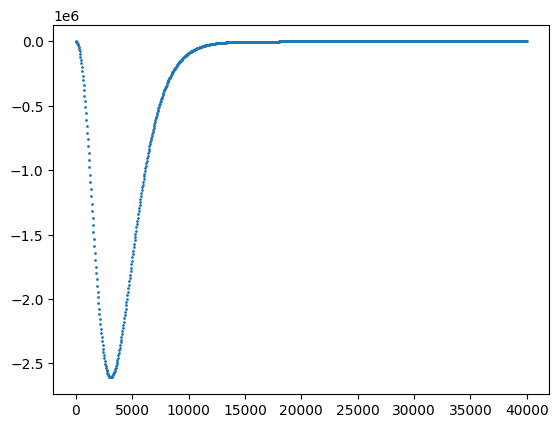

In [22]:
import numpy as np
from scipy.integrate import quad

T = 1000
mu_nu = 100
up = 4000000

def integrand(k):
    tmp = 0
    for sgn in [-1,1]:
        fd_pos = Solver._fd(k, sgn * mu_nu, -T)
        fd_neg = Solver._fd(k, sgn * mu_nu, T)
        tmp += k**2 * (
            fd_pos * np.log(np.clip(fd_pos, 1e-300, 1.0)) +
            fd_neg * np.log(np.clip(fd_neg, 1e-300, 1.0))
        )
    return tmp

val, _ = quad(
    integrand, 0, up,
    epsabs=1e-10, epsrel=1e-8,
    limit=500,  # <-- allow much deeper subdivision
    points=[abs(mu_nu)]  # <-- inform quadrature near peak
)

#entro = -4 * np.pi * val / (2 * np.pi)**3
#entro

import matplotlib.pyplot as plt

x = np.linspace(1,40000,1000)
y = np.array([integrand(ele) for ele in x])

plt.scatter(x, y, s=1)

In [23]:
Solver.neutrino_test(T=1000000, mu_nu=10, up=1000000000)

0.9072923540699703

In [2]:
from RMFsolver.phase_velocity import P_f

P_f(300, 100, 0), P_f(300, 100, 10)

(np.float64(48801727.79707178), 50219757.260399565)

In [3]:
import numpy as np
from RMFsolver.phase_velocity import PQM

def P_f_old(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

def PQM_old(muB, muK, B_one_forth):
    m_s = 100
    B = B_one_forth**4
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f_old(muB/3 - muK/2, m_s) - B

PQM_old(1000, 70, 165), PQM(1000, 70, 165, 0.4, 100,)

(np.float64(180373327.42063797), np.float64(180373327.42063797))

In [2]:
from RMFsolver import Solver
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para

pre = Solver.RMFpressureSYM(
    #nbext = 0.16*const.MeV_fm**3,
    input_num =  1000,#0.16*const.MeV_fm**3, 
    input_type = "muB", 
    Trmf = 100, 
    para = para.paraIUF,
    sigma_init = 30,
    w0_init = 20,
    mub_init = 990,
    #mu_e_init = 100,
    verb = True
)

print(f"{pre:.5e}")

Accuracy not achieved, check functions > 10^(-6)
Accuracy not achieved, check functions > 10^(-6)
6.42115e+08


In [101]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu
from RMFsolver.Solver import RMFpressureSYM
from RMFsolver.Solver import RMFpressurePNM
from RMFsolver.Solver import pressure_RMF

from RMFsolver.phase_velocity import P_f, PQM, extract_contour_coords, _aQstar_and_other_stuff, _vNtoQ_formula

def PNM(mu_B, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve_mu(
            mub = mu_B,
            Trmf = Temp,
            para = param,
            sigma_init = 30,
            w0_init = 20,
            r03_init = -3,
            mu_e_init = 50,
            verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(
            input_num = mu_B,
            input_type = "muB", 
            Trmf = Temp, 
            para = param, 
            sigma_init = 30, 
            w0_init = 20, 
            r03_init = -3, 
            mub_init = 990,
            verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(
            input_num = mu_B,
            input_type = "muB", 
            Trmf = Temp, 
            para = param, 
            sigma_init = 30, 
            w0_init = 20, 
            mub_init = 990,
            verb = False
            )
        return float(pre.item())

    else:
        print("Nuclear matter type not defined...")
        return None

T = 0
B_SQM = 169.5
DelP = 1e+8
m_s = 100
param = para.paraQMCRMF3
NM_type = "Beta_eq"

P_diff = lambda x: PQM(x, 0, B_SQM, T, 100,) - PNM(x, T)
P_diff(990)

-45068700.88467834

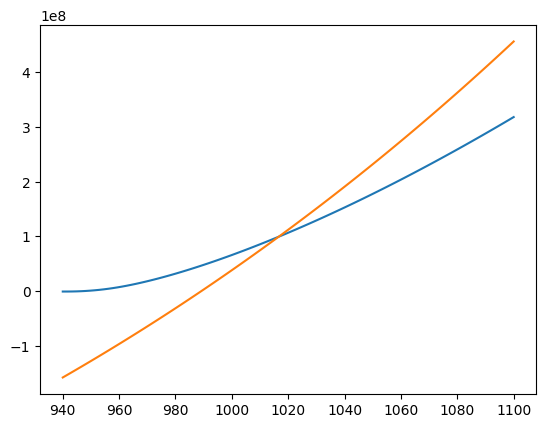

In [102]:
mubb = np.linspace(940, 1100, 100)
P_NM = np.array([PNM(x, T) for x in mubb])
P_QM = np.array([PQM(x, 0, B_SQM, T, m_s) for x in mubb])

plt.plot(mubb, P_NM)
plt.plot(mubb, P_QM)

In [104]:
NM_type = "Beta_eq"
PNM(990, 0), PQM(990, 0, B_SQM, 0, 100,)

(48069326.20755599, 3000625.3228776455)

In [139]:
muB_crit = fsolve(P_diff, 1050)[0]
P_crit = PNM(muB_crit, Temp=T)
muB_crit

np.float64(1016.623663959035)

In [106]:
PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
muB_N = fsolve(PNM_minus_PShift, 1050)[0]

muB_N

np.float64(1058.353188507901)

In [107]:
PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

muB_Q

np.float64(1042.110479743358)

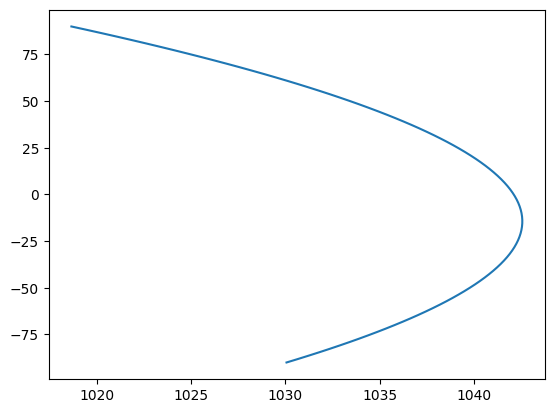

In [108]:
muB_list = np.linspace(940, 1100, 100)
muK_list = np.linspace(-90, 90, 100)
muB_grid, muK_grid = np.meshgrid(muB_list, muK_list)
P_QM = np.array([[PQM(i, j, B_SQM, T, m_s) for i in muB_list] for j in muK_list])
muB_contour_coor_num, muK_contour_coor_num = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit+DelP)

plt.plot(muB_contour_coor_num, muK_contour_coor_num)

In [53]:
import numpy as np
from scipy.optimize import root_scalar

def extract_contour_coords_ana(func, x_range, y_list, level, bracket=None, method='brentq'):
    '''
    Extract coordinates (x, y) satisfying func(x, y) = level using root finding.

    Parameters:
    - func   : function of (x, y) returning a scalar (e.g., func = lambda x, y: f(x, y))
    - x_range: tuple (x_min, x_max), search interval for x at each y
    - y_list : 1D array of y values to scan over
    - level  : contour level (constant value)
    - bracket: optional custom bracket (x_min, x_max), overrides x_range
    - method : root-finding method, default is 'brentq'

    Returns:
    - x_coords: array of x values where func(x, y) = level
    - y_coords: array of y values (corresponding to input y_list)
    '''

    x_coords = []
    y_coords = []

    x_min, x_max = bracket if bracket else x_range

    for y in y_list:
        f_root = lambda x: func(x, y) - level
        try:
            sol = root_scalar(f_root, bracket=[x_min, x_max], method=method)
            if sol.converged:
                x_coords.append(sol.root)
                y_coords.append(y)
        except ValueError:
            continue  # skip if no root in bracket

    return np.array(x_coords), np.array(y_coords)

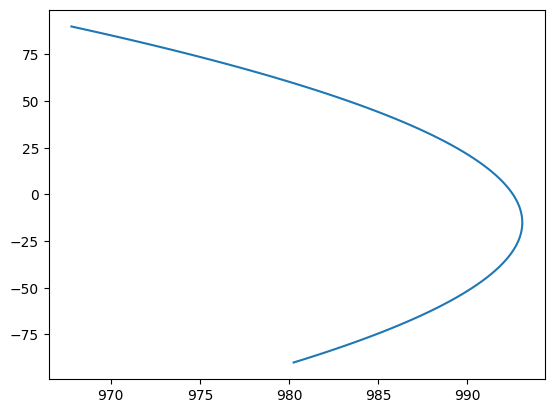

In [73]:
# obtaining Q star
#muB_list = np.linspace(940, 1100, 100)
muK_list = np.linspace(-90, 90, 100)
#muB_grid, muK_grid = np.meshgrid(muB_list, muK_list)
#P_QM = np.array([[PQM(i, j, B_SQM, T, m_s) for i in muB_list] for j in muK_list])
muB_contour_coor, muK_contour_coor = extract_contour_coords_ana(
    func = lambda mubb, mukk: PQM(mubb, mukk, B_SQM, T, m_s),
    x_range = (940, 1100),
    y_list = muK_list,
    level = P_crit + DelP
    )

plt.plot(muB_contour_coor, muK_contour_coor)

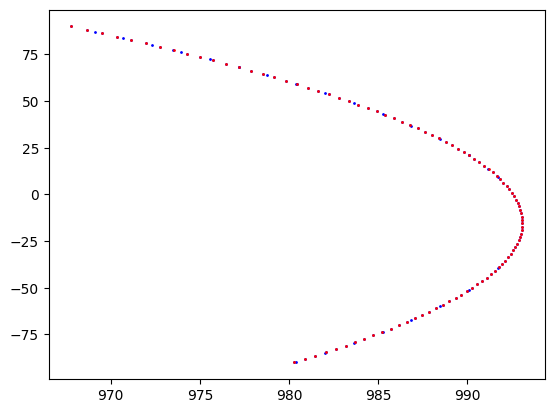

In [74]:
plt.scatter(muB_contour_coor_num, muK_contour_coor_num, s=1, c='b')
plt.scatter(muB_contour_coor, muK_contour_coor, s=1, c='r')

1


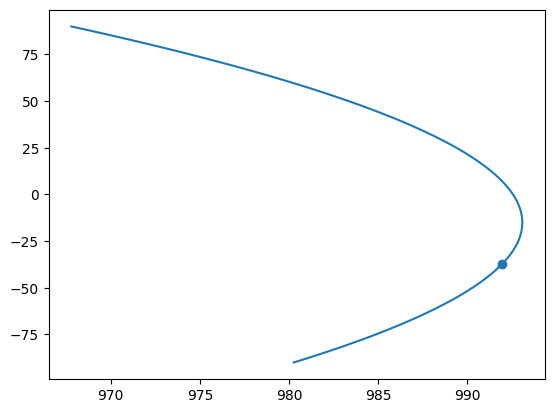

In [76]:
from scipy.optimize import approx_fprime
from scipy.signal import argrelextrema
PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, m_s, T)

mu_average = []
epsilon = np.sqrt(np.finfo(float).eps)
for i in range(len(muB_contour_coor)):
    muB_Qstar = muB_contour_coor[i]
    muK_Qstar = muK_contour_coor[i]
    Qstar = np.array([muB_Qstar, muK_Qstar])
    grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
    nB_Qstar = grad[0]
    nK_Qstar = grad[1]
    mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
difference = np.abs(np.array(mu_average) - muB_N)
minima_ind = argrelextrema(difference, np.less)[0]
print(len(minima_ind))
muB_Qstar_down = muB_contour_coor[minima_ind[0]]
muK_Qstar_down = muK_contour_coor[minima_ind[0]]
#muB_Qstar_up = muB_contour_coor[minima_ind[1]]
#muK_Qstar_up = muK_contour_coor[minima_ind[1]]

plt.plot(muB_contour_coor, muK_contour_coor)
#plt.scatter(muB_Qstar_up, muK_Qstar_up)
plt.scatter(muB_Qstar_down, muK_Qstar_down)

In [115]:
from scipy.optimize import least_squares
from numdifftools import Gradient
import numpy as np

def find_muB_muK_star(PQM, P_target, C, B_one_forth, T, ms, upB=5000,
                  initial_guess=(1000.0, 30.0)):
    '''
    Solves:
      1. PQM(muB, muK) = P_target
      2. muB + muK * (∂PQM/∂muK)/(∂PQM/∂muB) = C

    Returns:
      muB_star, muK_star
    '''

    def f(vec):
        muB, muK = vec
        return PQM(muB, muK, B_one_forth, T, ms, upB)

    grad_f = Gradient(lambda v: f(v), step=1e-3)

    def system(vec):
        muB, muK = vec
        f_val = f([muB, muK])
        grad = grad_f([muB, muK])
        df_dmuB, df_dmuK = grad[0], grad[1]

        slope_term = 1e6 if np.abs(df_dmuB) < 1e-6 else muB + muK * (df_dmuK / df_dmuB)
        return [f_val - P_target, slope_term - C]

    sol = root(system, initial_guess, method='hybr')
    if not sol.success:
        raise RuntimeError(f"Root finding failed: {sol.message}")

    return sol.x[0], sol.x[1]

In [140]:
muB_star, muK_star = find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
print(f"muB* = {muB_star:.3f}, muK* = {muK_star:.3f}")

muB* = 1020.184, muK* = 86.587


In [141]:
muB_crit, muB_N, muB_Q, DelP - 1e8, T

(np.float64(1016.623663959035),
 np.float64(1058.353188507901),
 np.float64(1042.110479743358),
 0.0,
 0)

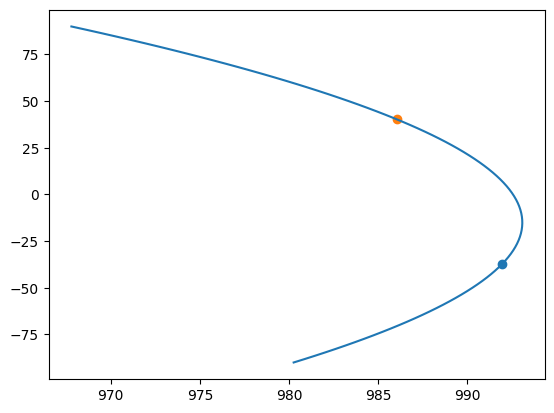

In [83]:
plt.plot(muB_contour_coor, muK_contour_coor)
#plt.scatter(muB_Qstar_up, muK_Qstar_up)
plt.scatter(muB_Qstar_down, muK_Qstar_down)
plt.scatter(muB_star, muK_star)

In [120]:
muB_star, muK_star

(np.float64(1020.1838378663471), np.float64(86.58725694998408))

In [181]:
epsilon = np.sqrt(np.finfo(float).eps)
PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
nB_Qstar = grad_Qstar[0]
nK_Qstar = grad_Qstar[1]
nB_Qstar, nK_Qstar

(np.float64(4001664.0), np.float64(1753296.0))

In [185]:
grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
nB_Q = grad_Q[0]
nK_Q = grad_Q[1]

PNM_wrap = lambda x: PNM(x, T)
grad_N = approx_fprime(muB_N, PNM_wrap, epsilon)
nB_N = grad_N

aQstar = (nK_Qstar - nK_Q)/nB_Q

aN = (nB_N - nK_Q) / nB_Q

aQstar, aN

(np.float64(0.40210331226739543), array([0.48305959]))

In [184]:
nK_Q/nB_Q

np.float64(0.06693018706809656)

In [146]:
from numdifftools import Derivative

PQM_wrap = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
ddP_ddmuK = Derivative(PQM_wrap, n=2)
dP_dmuB = Derivative(PQM_wrap, n=1)
chiK_Q = ddP_ddmuK(muB_Q)
nB_Q = dP_dmuB(muB_Q)
aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)

aQstar

np.float64(0.30999482101259923)

In [138]:
from RMFsolver.phase_velocity import _vNtoQ_formula

_vNtoQ_formula(100, aQstar, aN,)

array([94.91310535])

In [126]:
nK_Q , nK_Qstar

(np.float64(258432.0), np.float64(1749032.0))

# Step-by-step code for $v_{N\to Q}$ calculation

In [74]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve
from scipy.optimize import approx_fprime
from scipy.optimize import root_scalar
from scipy.optimize import root
from numdifftools import Gradient
from numdifftools import Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu
from RMFsolver.Solver import RMFpressureSYM
from RMFsolver.Solver import RMFpressurePNM
from RMFsolver.Solver import pressure_RMF

from RMFsolver.phase_velocity import P_f, n_B, PQM, _vNtoQ_formula

def PNM(mu_B, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve_mu(
            mub = mu_B,
            Trmf = Temp,
            para = param,
            sigma_init = 30,
            w0_init = 20,
            r03_init = -3,
            mu_e_init = 50,
            verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(
            input_num = mu_B,
            input_type = "muB", 
            Trmf = Temp, 
            para = param, 
            sigma_init = 30, 
            w0_init = 20, 
            r03_init = -3, 
            mub_init = 990,
            verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(
            input_num = mu_B,
            input_type = "muB", 
            Trmf = Temp, 
            para = param, 
            sigma_init = 30, 
            w0_init = 20, 
            mub_init = 990,
            verb = False
            )
        return float(pre.item())

    else:
        print("Nuclear matter type not defined...")
        return None

T = 17
B_SQM = 180
DelP = 1e+8
m_s = 100
param = para.paraQMCRMF3
NM_type = "PNM"
method = "analytical"

P_diff = lambda x: PQM(x, 0, B_SQM, T, 100,) - PNM(x, T)
P_diff(990)

-231169333.50803068

In [75]:
# solve for critical point
P_diff = lambda x: PQM(x, 0, B_SQM, T, m_s) - PNM(x, T)
muB_crit = fsolve(P_diff, 1050)[0]
P_crit = PQM(muB_crit, 0, B_SQM, T, m_s)

muB_crit, P_crit

(np.float64(1114.228912329543), 361230872.09060144)

In [73]:
420255731.45624614 / 1e8 #/255869036.06335878

4.202557314562461

In [76]:
# solve for points Q and N at beta eq.
PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
muB_N = fsolve(PNM_minus_PShift, 1050)[0]

PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

muB_Q, muB_N

(np.float64(1133.2847539540062), np.float64(1145.3179179670537))

In [77]:
if method == "numerical":
    def find_muB_muK_star(PQM, P_target, C, B_one_forth, T, ms, upB=5000, initial_guess=(1020.0, 30.0)):
        '''
        Solves:
          1. PQM(muB, muK) = P_target
          2. muB + muK * (∂PQM/∂muK)/(∂PQM/∂muB) = C
    
        Returns:
          muB_star, muK_star
        '''
    
        def f(muB, muK):
            return PQM(muB, muK, B_one_forth, T, ms, upB)
    
        def dPQM_dmuB(muB, muK):
            mu_u = muB / 3
            mu_d = muB / 3 + muK / 2
            mu_s = muB / 3 - muK / 2
    
            n_u = n_B(mu_u, 0, T, upB)
            n_d = n_B(mu_d, 0, T, upB)
            n_s = n_B(mu_s, ms, T, upB)
    
            return (1/3) * (n_u + n_d + n_s)
    
        def dPQM_dmuK(muB, muK):
            mu_d = muB / 3 + muK / 2
            mu_s = muB / 3 - muK / 2
    
            n_d = n_B(mu_d, 0, T, upB)
            n_s = n_B(mu_s, ms, T, upB)
    
            return 0.5 * (n_d - n_s)
    
        def system(vec):
            muB, muK = vec
            P_val = f(muB, muK)
            df_dmuB = dPQM_dmuB(muB, muK)
            df_dmuK = dPQM_dmuK(muB, muK)
    
            # Reformulated second equation to avoid division instability
            eq1 = P_val - P_target
            eq2 = df_dmuB * muB + df_dmuK * muK - df_dmuB * C
    
            return [eq1, eq2]
    
        from scipy.optimize import root
    
        sol = root(system, initial_guess, method='hybr')
        if not sol.success:
            raise RuntimeError(f"Root finding failed: {sol.message}")
    
        return sol.x[0], sol.x[1]
    
    epsilon = np.sqrt(np.finfo(float).eps)
    muB_star, muK_star = find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
    PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
    grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]
    grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]
    aQstar = (nK_Qstar - nK_Q)/nB_Q
    print(aQstar)

elif method == "analytical":
    PQM_wrap = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    ddPQM_ddmuK = Derivative(PQM_wrap, n=2)
    dPQM_dmuB = Derivative(PQM_wrap, n=1)
    chiK_Q = ddPQM_ddmuK(muB_Q)
    nB_Q = dPQM_dmuB(muB_Q)
    aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
    muB_star = muB_Q
    print(aQstar)

else:
    print("shit")

0.25357798811848825


In [41]:
# calculating aN
PNM_wrap = lambda x: PNM(x, T)
dPNM_dmuB = Derivative(PNM_wrap, n=1)
nB_N = dPNM_dmuB(muB_N)
aN = nB_N / nB_Q

In [42]:
aQstar, aN

(np.float64(0.1366994121691231), np.float64(0.5595997691393817))

In [43]:
from RMFsolver.phase_velocity import _vNtoQ_formula

_vNtoQ_formula(T, aQstar, aN=aN, muQ=muB_star/3)

np.float64(46.59991884520125)

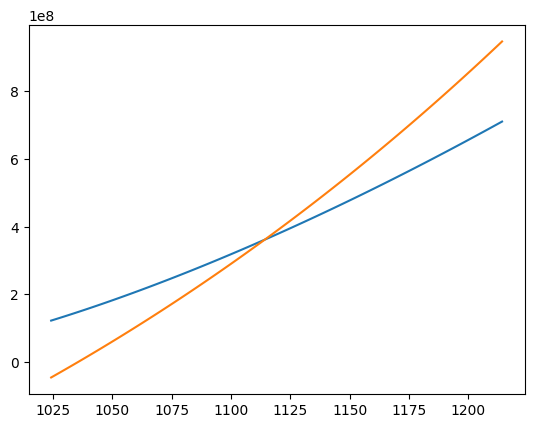

In [78]:
mubb = np.linspace(muB_crit-90, muB_crit+100, 100)
P_NM = np.array([PNM(x, T) for x in mubb])
P_QM = np.array([PQM(x, 0, B_SQM, T, m_s) for x in mubb])

plt.plot(mubb, P_NM)
plt.plot(mubb, P_QM)

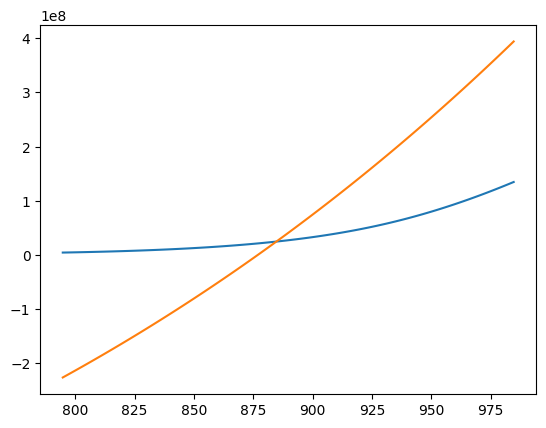

In [36]:
mubb = np.linspace(muB_crit-90, muB_crit+100, 100)
P_NM = np.array([PNM(x, T) for x in mubb])
P_QM = np.array([PQM(x, 0, B_SQM, T, m_s) for x in mubb])

plt.plot(mubb, P_NM)
plt.plot(mubb, P_QM)

In [13]:
from RMFsolver.phase_velocity import vNtoQ
import RMFsolver.RMFparameter as para
import time

start = time.time()
ve = vNtoQ(
    T = 2,                    # temperature in MeV
    B_SQM = 180,              # Bag constant for quark matter bag model, in MeV
    DelP = 1e+7,              # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 400,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM",          # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "numerical"
)
end = time.time()

ve

np.float64(178.72550141225597)

In [19]:
#np.linspace(10,400,25)
np.array([10+16*i for i in range(25)])

array([ 10,  26,  42,  58,  74,  90, 106, 122, 138, 154, 170, 186, 202,
       218, 234, 250, 266, 282, 298, 314, 330, 346, 362, 378, 394])

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from RMFsolver.phase_velocity import vNtoQ
import RMFsolver.RMFparameter as para
import time

N = 25
meth = "numerical"

TT = np.linspace(1, 25, N)
MM = np.linspace(10, 400, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ(
            T = TT[i],
            B_SQM = 180,
            DelP = 1e+7,
            m_s = MM[j],
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j)

np.save("MS_T_N="+str(N)+"_"+meth+".npy", V)

0 0


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:68: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
1 0
1 1
1 2


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:68: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17


...

22 23


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


22 24
23 0
23 1
23 2
23 3
23 4
23 5
23 6
23 7
23 8
23 9
23 10
23 11
23 12
23 13
23 14
23 15
23 16
23 17
23 18
23 19
23 20
23 21
23 22


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


23 23
23 24
24 0
24 1
24 2
24 3
24 4
24 5
24 6
24 7
24 8
24 9
24 10
24 11
24 12
24 13
24 14
24 15
24 16
24 17
24 18
24 19
24 20
24 21
24 22
24 23
24 24


Text(0, 0.5, 'T (MeV)')

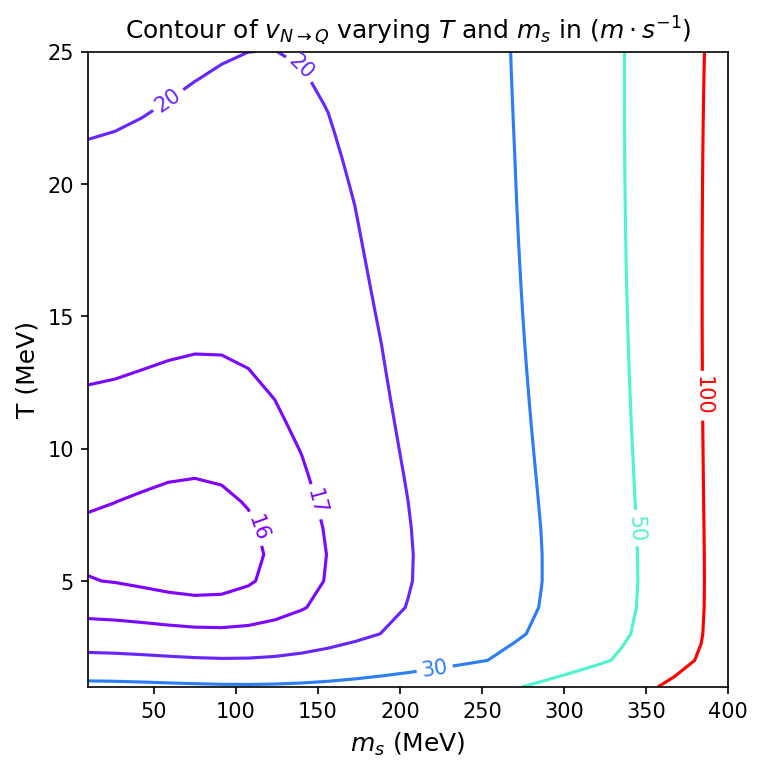

In [11]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
T_grid, M_grid = np.meshgrid(TT, MM)  # note BB first for x, TT for 

#V_old = np.load("B_T.npy")
#B_grid_old, T_grid_old = np.meshgrid(np.linspace(165, 195, 20), np.linspace(0.1, 23, 20))

contours = plt.contour(M_grid, T_grid, V.T, levels = np.array([16, 17, 20, 30, 50, 100, ]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}$ varying $T$ and $m_s$ in $(m\cdot s^{-1})$")
plt.xlabel(r"$m_s$ (MeV)", fontsize=12)
plt.ylabel("T (MeV)", fontsize=12)

#plt.savefig("MS_T_N="+str(N)+"_"+meth+".pdf", dpi=300)  # Increase DPI as needed

In [10]:
V.max(), V.min()

(np.float64(416.4361083998987), np.float64(15.696249053268302))

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM

n0 = 0.16 * const.MeV_fm**3

In [2]:
import numpy as np
import matplotlib.pyplot as plt

N = 30
meth = "numerical"
nc = 2*n0
m_strange = 0

TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 75, int(N*3/5))])
DD = np.linspace(0.001*nc, 0.03*nc, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ_nc(
            T = TT[i],
            n_crit = nc,
            Deln = DD[j],
            m_s = m_strange,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j, V[i,j])

np.save("Deln_T_ncrit="+str(nc/n0)+".npy", V)

0 0 2.8737068232147105
0 1 4.795063912843888
0 2 6.664743942349858
0 3 8.525646620185546
0 4 10.390663383450336
0 5 12.261724597577114
0 6 14.142662327770624
0 7 16.035712874009985
0 8 17.936311799434907
0 9 19.84693642153433
0 10 21.76531752248833
0 11 23.69495487011968
0 12 25.640156540695298
0 13 27.585649905197123
0 14 29.544489362664084
0 15 31.513228610512737
0 16 33.487073125236904
0 17 35.4763371831372
0 18 37.46899729080895
0 19 39.469907084554684
0 20 41.48232941574223
0 21 43.49578269599118
0 22 45.52770085092758
0 23 47.559088183002025
0 24 49.601236434207195
0 25 51.64877571201639
0 26 53.71012219335228
0 27 55.76749256942391
0 28 57.84239788110253
0 29 59.925086981744435
1 0 2.716762114338615
1 1 4.019014934909193
1 2 5.124446902255178
1 3 6.141631365691683
1 4 7.108008564708179
1 5 8.043509962555232
1 6 8.957446693498833
1 7 9.859675259068338
1 8 10.749679139057069
1 9 11.633669574560344
1 10 12.513084458509194
1 11 13.388829841515424
1 12 14.262075738610081
1 13 15.1359

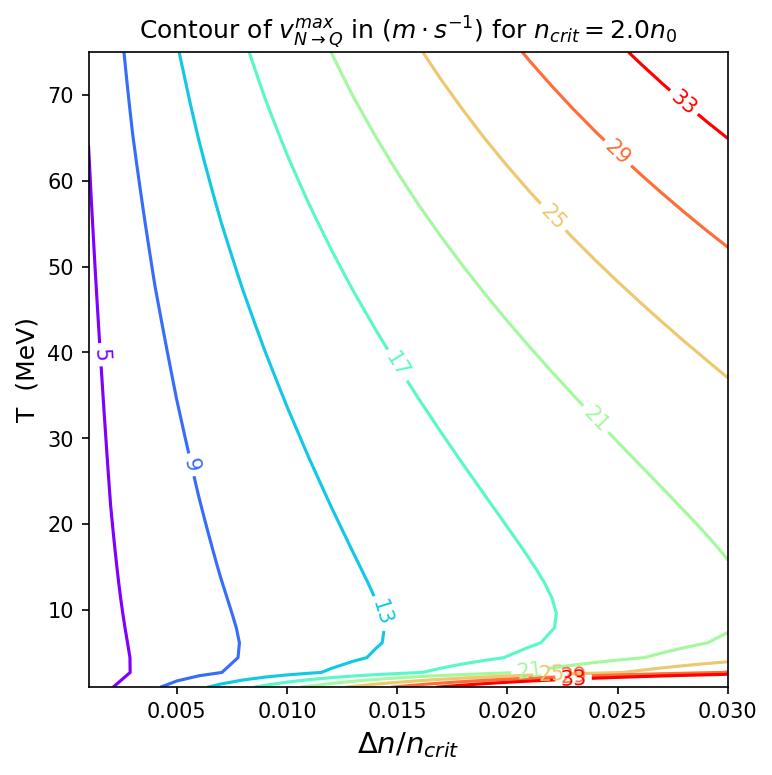

In [23]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
T_grid, D_grid = np.meshgrid(TT, DD)  # note BB first for x, TT for 

#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid/nc, T_grid, V.T, levels = np.array([5, 9, 13, 17, 21, 25, 29, 33]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}^{max}$ in ($m\cdot s^{-1}$) for $n_{crit}=$"+str(nc/n0)+r"$n_0$" )
plt.xlabel(r"$\Delta n / n_{crit}$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

plt.savefig("Deln_T_ncrit="+str(nc/n0)+".pdf", dpi=300)  # Increase DPI as needed

In [4]:
V.min(), V.max()

(np.float64(2.716762114338615), np.float64(59.925086981744435))